<a href="https://colab.research.google.com/github/bimaadiwijaya8/PCVK26_05_BimaAdiwijaya/blob/main/P7_Praktikum_05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Link Github: https://github.com/bimaadiwijaya8/PCVK26_05_BimaAdiwijaya/blob/main/P7_Praktikum_05.ipynb*

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

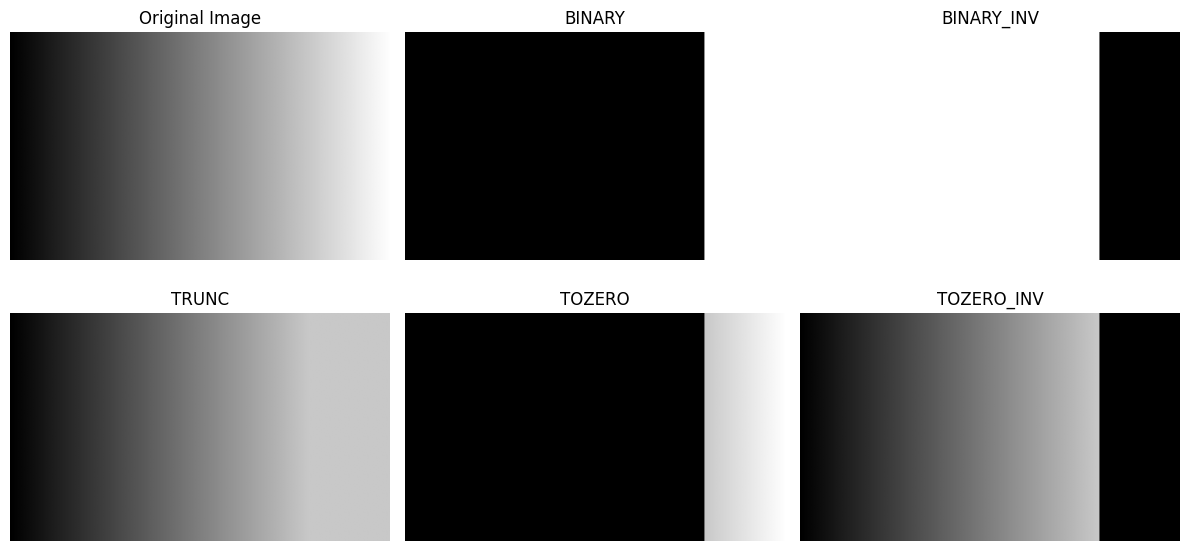

In [7]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Membuat gambar gradasi (Original Image) seperti contoh
# Membuat gambar abu-abu dari gelap ke terang berukuran 300x500 piksel
img = np.tile(np.linspace(0, 255, 500, dtype=np.uint8), (300, 1))

# Tentukan nilai threshold dan nilai maksimal piksel
thresh_val = 200
max_val = 255

# 2. Implementasi Global Threshold secara manual sesuai ketentuan tabel

# BINARY: > thresh menjadi nilai maksimal, <= thresh menjadi 0
img_binary = np.where(img > thresh_val, max_val, 0).astype(np.uint8)

# BINARY_INV: > thresh menjadi 0, <= thresh menjadi nilai maksimal[cite: 2]
img_binary_inv = np.where(img > thresh_val, 0, max_val).astype(np.uint8)

# TRUNC: > thresh menjadi thresh, <= thresh nilai asli tetap[cite: 2]
img_trunc = np.where(img > thresh_val, thresh_val, img).astype(np.uint8)

# TOZERO: > thresh nilai asli tetap, <= thresh menjadi 0[cite: 2]
img_tozero = np.where(img > thresh_val, img, 0).astype(np.uint8)

# TOZERO_INV: > thresh menjadi 0, <= thresh nilai asli tetap[cite: 2]
img_tozero_inv = np.where(img > thresh_val, 0, img).astype(np.uint8)

# 3. Menampilkan hasil menggunakan Matplotlib (menyerupai tata letak pada soal)
titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, img_binary, img_binary_inv, img_trunc, img_tozero, img_tozero_inv]

plt.figure(figsize=(12, 6))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

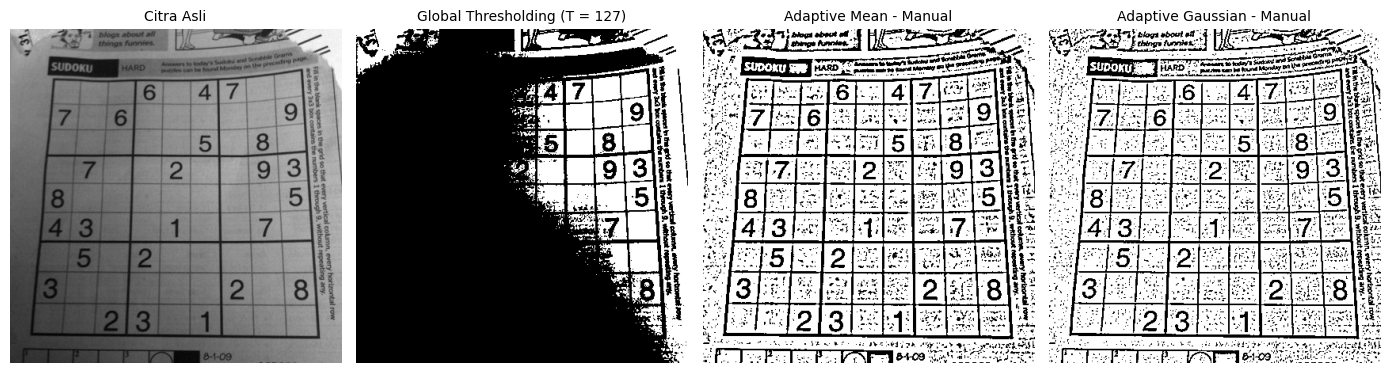

In [9]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Memuat citra Sudoku secara grayscale (pastikan path gambar sesuai di komputer/Colab Anda)
# Contoh menggunakan cv.imread('sudoku.png', 0)
img = cv.imread('/content/drive/MyDrive/PCVK/Gambar/sudoku-original.jpg', 0)

# Jika Anda ingin mencoba langsung tanpa file eksternal, Anda bisa membaca citra grayscale
# img = cv.cvtColor(cv.imread('sudoku.jpg'), cv.COLOR_BGR2GRAY)

# 2. Global Threshold Manual (T = 127)
T = 127
global_thresh = np.where(img > T, 255, 0).astype(np.uint8)

# Fungsi bantuan untuk melakukan padding agar ukuran citra tetap sama setelah operasi jendela
def pad_image(image, pad_size):
    return np.pad(image, pad_size, mode='edge')

# 3. Adaptive Mean Manual (Ukuran jendela 11x11, C = 2)
def manual_adaptive_mean(image, block_size, C):
    h, w = image.shape
    pad = block_size // 2
    padded = pad_image(image, pad)
    output = np.zeros((h, w), dtype=np.uint8)

    # Menghitung mean lokal menggunakan integral image (atau loop sederhana per piksel)
    for i in range(h):
        for j in range(w):
            window = padded[i:i+block_size, j:j+block_size]
            mean_val = np.mean(window)
            # Jika piksel > (mean - C), set 255 (putih), else 0 (hitam)
            if image[i, j] > (mean_val - C):
                output[i, j] = 255
            else:
                output[i, j] = 0
    return output

# 4. Adaptive Gaussian Manual (Ukuran jendela 11x11, sigma = 2, C = 2)
def manual_adaptive_gaussian(image, block_size, sigma, C):
    h, w = image.shape
    pad = block_size // 2
    padded = pad_image(image, pad)
    output = np.zeros((h, w), dtype=np.uint8)

    # Membuat kernel Gaussian 2D secara manual
    ax = np.arange(-pad, pad + 1)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    kernel = kernel / np.sum(kernel) # Normalisasi kernel

    for i in range(h):
        for j in range(w):
            window = padded[i:i+block_size, j:j+block_size].astype(np.float32)
            # Menghitung weighted sum (Gaussian local threshold)
            gauss_val = np.sum(window * kernel)

            if image[i, j] > (gauss_val - C):
                output[i, j] = 255
            else:
                output[i, j] = 0
    return output

# Menjalankan fungsi manual
block_size = 11
C = 2
sigma = 2

adaptive_mean_img = manual_adaptive_mean(img, block_size, C)
adaptive_gauss_img = manual_adaptive_gaussian(img, block_size, sigma, C)

# 5. Menampilkan hasil perbandingan menggunakan Matplotlib
titles = ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual']
images = [img, global_thresh, adaptive_mean_img, adaptive_gauss_img]

plt.figure(figsize=(14, 5))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i], fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

93


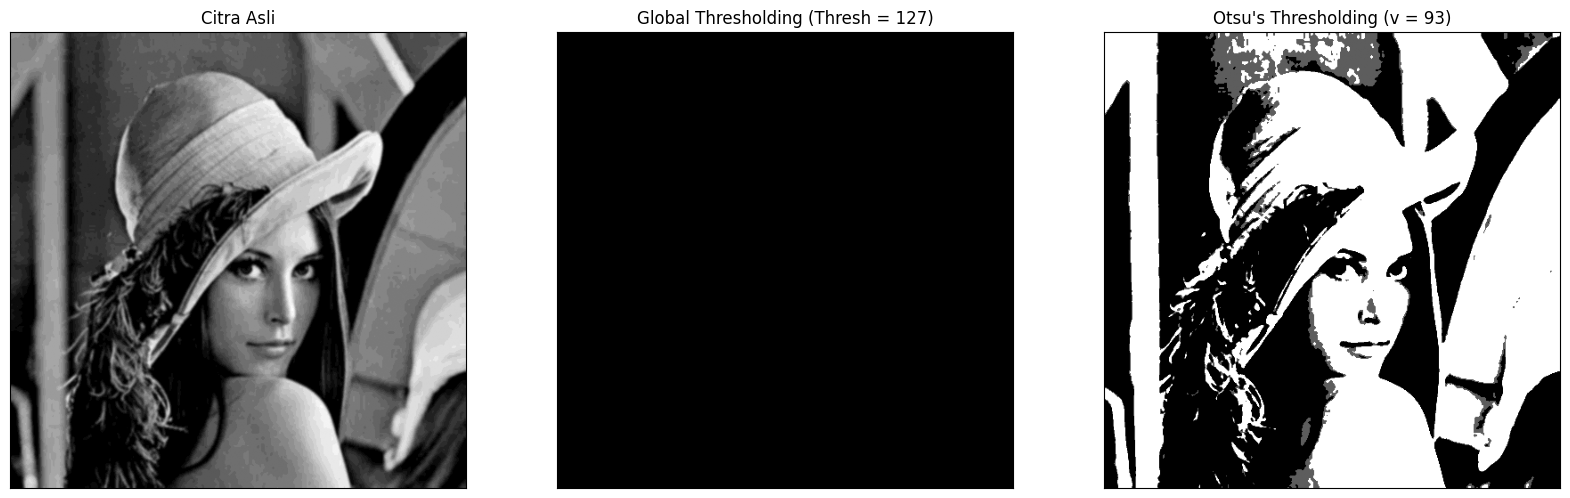

In [11]:
filename = ('/content/drive/MyDrive/PCVK/Gambar/lena_gs_lc2.jpg')
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5,5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb) if pcb > 0 else 0
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf) if pcf > 0 else 0
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = " + str(otsu_thresh) + ")")
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

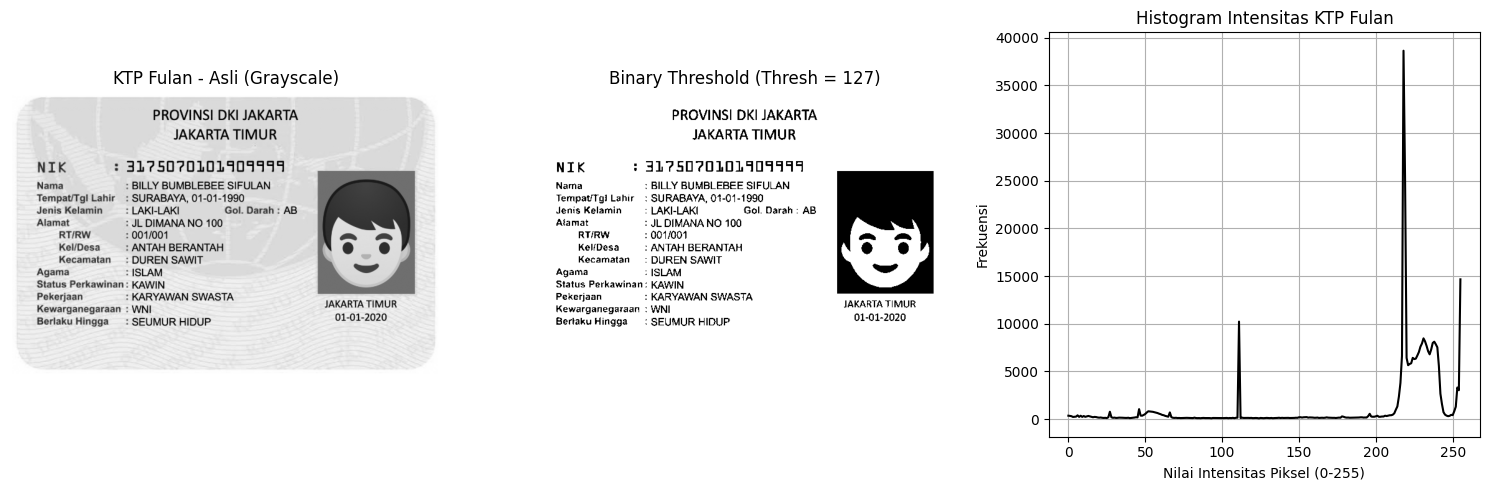

In [14]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Memuat citra KTP_Fulan (sesuaikan path file di Google Drive Anda)
# Pastikan file KTP_Fulan sudah di-upload atau di-mount dari Drive
ktp_path = '/content/drive/MyDrive/PCVK/Gambar/ktp4.jpg' # Ganti path sesuai lokasi Anda
img_ktp = cv.imread(ktp_path, 0)

# Jika gambar tidak ditemukan lewat path, pastikan membaca dari direktori lokal Colab jika diunggah langsung
if img_ktp is None:
    # Contoh pembacaan alternatif jika di-upload langsung
    img_ktp = cv.imread('ktp4.jpg', 0)

# 2. Terapkan Binary Thresholding pada KTP_Fulan dengan thresh = 127
thresh = 127
ret, ktp_binary = cv.threshold(img_ktp, thresh, 255, cv.THRESH_BINARY)

# 3. Menghitung Histogram KTP dan Citra Lena (jika citra Lena tersedia)
hist_ktp = cv.calcHist([img_ktp], [0], None, [256], [0, 256])

# 4. Plotting Perbandingan Citra KTP Asli, Hasil Binary Threshold, dan Histogramnya
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_ktp, cmap='gray')
plt.title('KTP Fulan - Asli (Grayscale)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(ktp_binary, cmap='gray')
plt.title(f'Binary Threshold (Thresh = {thresh})')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.plot(hist_ktp, color='black')
plt.title('Histogram Intensitas KTP Fulan')
plt.xlabel('Nilai Intensitas Piksel (0-255)')
plt.ylabel('Frekuensi')
plt.grid(True)

plt.tight_layout()
plt.show()

### Pertanyaan:
Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam semuanya? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas (Thresh) supaya gambar Lena ini masih terlihat?

### Jawaban:

1. **Alasan Hasil Binary Thresholding Berwarna Hitam Semua:**
   * Citra `lena_gs_lc2.jpg` merupakan citra dengan tingkat keabuan yang sangat gelap (memiliki intensitas piksel yang rendah atau underexposed).
   * Nilai ambang batas (*threshold*) yang digunakan secara *default* pada kode adalah `thresh = 127`.
   * Berdasarkan analisis histogram, distribusi intensitas piksel pada citra tersebut terkonsentrasi di sebelah kiri (nilai pikselnya jauh di bawah 127, misalnya berkisar antara 0 hingga 50).
   * Karena hampir seluruh piksel pada gambar memiliki nilai yang **lebih kecil** daripada nilai ambang batas 127 ($\text{piksel} \le 127$), maka fungsi *Binary Thresholding* mengubah semua piksel tersebut menjadi nilai **0 (hitam)**.

2. **Angka Ambang Batas (*Thresh*) Supaya Gambar Lena Masih Terlihat:**
   * Supaya gambar Lena masih dapat terlihat dengan baik, nilai ambang batas (*thresh*) harus diturunkan agar berada di dalam rentang distribusi piksel citra tersebut.
   * Nilai *thresh* yang disarankan berkisar antara **30 sampai 50** (tergantung tingkat kecerahan spesifik pada citra tersebut), sehingga sebagian piksel objek dapat terdeteksi sebagai putih dan sebagian lainnya sebagai hitam.

### Analisis Perbandingan: Citra Lena vs KTP_Fulan pada Binary Thresholding

1. **Mengapa Hasil Binary Thresholding Citra Lena Berwarna Hitam Semua?**
   * **Alasan:** Citra `lena_gs_lc2.jpg` memiliki tingkat pencahayaan yang sangat rendah (*underexposed* / gelap). Berdasarkan analisis histogramnya, seluruh distribusi intensitas piksel terkonsentrasi di rentang nilai yang rendah (jauh di bawah angka 127).
   * Karena menggunakan ambang batas (*threshold*) standar $\text{thresh} = 127$, hampir semua piksel bernilai lebih kecil dari 127 ($\text{piksel} \le 127$), sehingga diubah menjadi **0 (hitam)** oleh operasi *binary thresholding*.
   * **Angka Ambang Batas (*Thresh*) Supaya Gambar Lena Terlihat:** Agar gambar Lena terlihat, nilai *thresh* harus diturunkan mendekati rata-rata gelap citranya, yaitu berkisar antara **30 sampai 50**.

2. **Perbandingan dengan Hasil pada KTP_Fulan (`ktp4.jpg`):**
   * **Karakteristik KTP:** Citra KTP biasanya didominasi oleh latar belakang kertas yang terang/putih (intensitas piksel tinggi di atas 150–200) serta teks/huruf berwarna hitam (intensitas piksel rendah di bawah 100). Histogramnya bersifat *bimodal* (memiliki dua puncak yang jelas).
   * **Hasil Thresholding KTP:** Ketika menggunakan $\text{thresh} = 127$, nilai tersebut berada tepat di tengah-tengah antara latar belakang terang dan teks gelap. Oleh karena itu, *Binary Thresholding* pada KTP **tidak menjadi hitam semua**, melainkan berhasil memisahkan teks (menjadi hitam/0) dengan latar belakang KTP (menjadi putih/255) secara jelas dan terbaca.

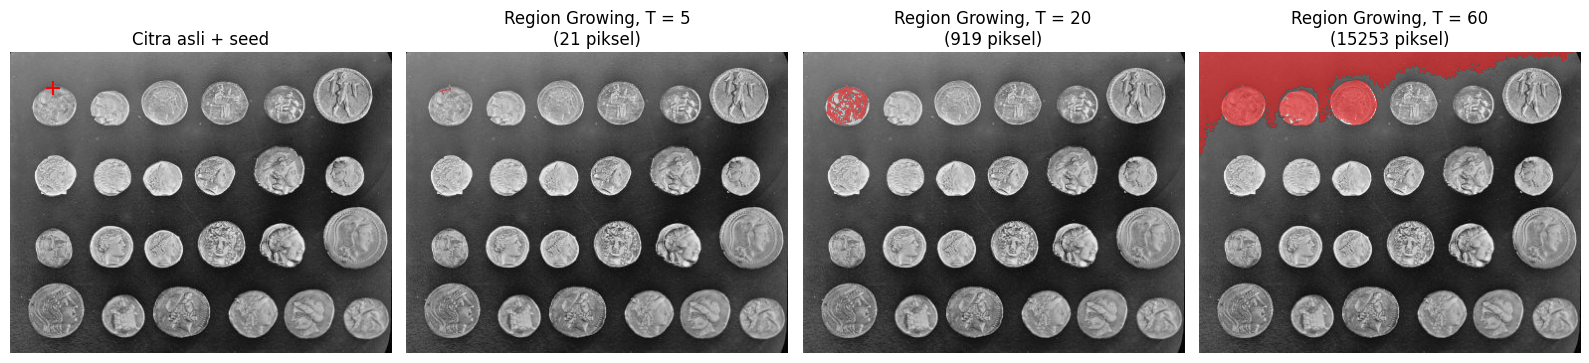

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

# 1. Ambil citra coins
gray = data.coins()

# 2. Tentukan koordinat seed sesuai contoh modul (baris, kolom)
seed = (36, 43)  # Koin di pojok kiri atas

# 3. Jalankan fungsi flood dengan berbagai nilai tolerance (T) sesuai ketentuan
tolerances = [5, 20, 60]
regions = []

for t in tolerances:
    reg = flood(gray, seed_point=seed, tolerance=t, connectivity=1)
    regions.append((t, reg))

# 4. Tampilkan hasil dalam bentuk grid (1 baris, 4 kolom: Asli, T=5, T=20, T=60)
plt.figure(figsize=(16, 4))

# Plot 1: Citra Asli + Titik Seed
plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.scatter(seed[1], seed[0], color='red', marker='+', s=100) # Tanda plus merah seperti di contoh
plt.title('Citra asli + seed')
plt.axis('off')

# Plot 2, 3, 4: Hasil Segmentasi untuk T = 5, 20, 60 dengan overlay merah
for i, (t, reg) in enumerate(regions):
    plt.subplot(1, 4, i + 2)
    plt.imshow(gray, cmap='gray')

    # Membuat overlay warna merah transparan pada area mask segmentasi
    overlay = np.zeros((*gray.shape, 4), dtype=np.float32)
    overlay[reg] = [1, 0, 0, 0.5] # Warna Merah dengan transparansi 0.5
    plt.imshow(overlay)

    pixel_count = np.sum(reg)
    plt.title(f'Region Growing, T = {t}\n({pixel_count} piksel)')
    plt.axis('off')

plt.tight_layout()
plt.show()

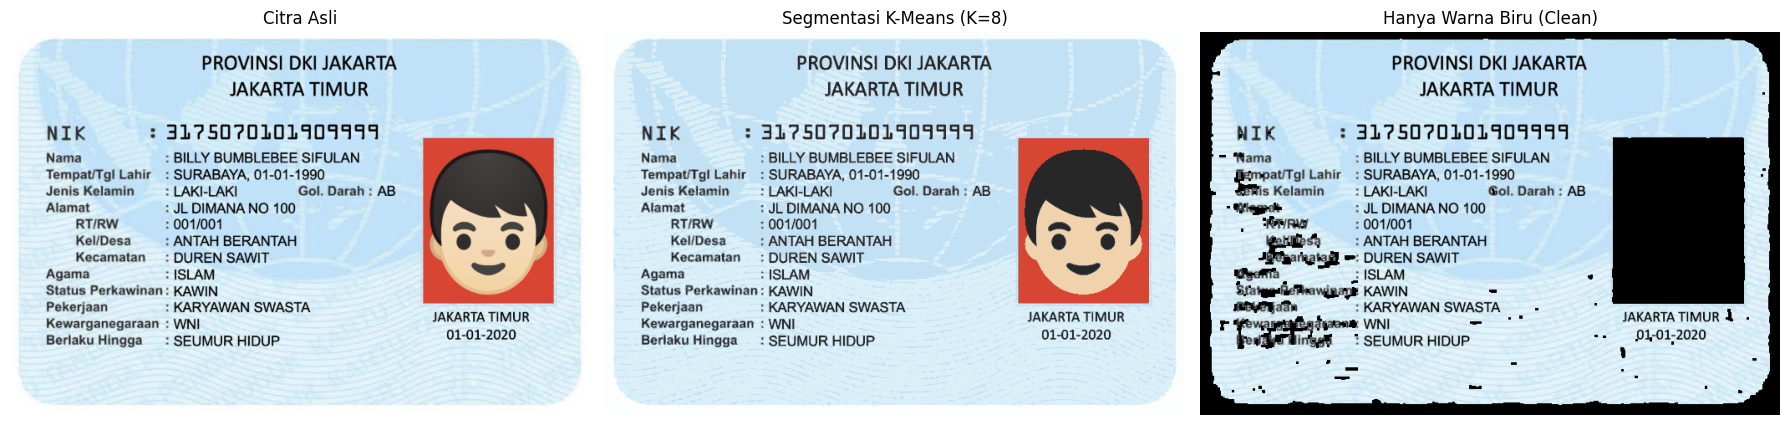

In [24]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Memuat citra KTP Fulan
filename = '/content/drive/MyDrive/PCVK/Gambar/ktp4.jpg' # Sesuaikan path Anda
img = cv.imread(filename)
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)

# Memisahkan channel HSV
H = hsv[:, :, 0]
S = hsv[:, :, 1]
V = hsv[:, :, 2]

# 2. Membuat mask untuk kelompok warna biru
mask = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)

# Membersihkan noise/bintik-bintik kecil di sekitar teks menggunakan operasi morfologi
mask_uint8 = mask.astype(np.uint8) * 255
kernel = np.ones((3,3), np.uint8)
mask_cleaned = cv.morphologyEx(mask_uint8, cv.MORPH_CLOSE, kernel)
mask_cleaned = cv.morphologyEx(mask_cleaned, cv.MORPH_OPEN, kernel)
final_mask = mask_cleaned > 0

# 3. Membuat citra "Hanya Warna Biru" yang lebih bersih dari noise hitam
hanya_biru = np.zeros_like(img_rgb)
hanya_biru[final_mask] = img_rgb[final_mask]

# (Opsional) Segmentasi K-Means (K=8)
pixel_values = img_rgb.reshape((-1, 3))
pixel_values = np.float32(pixel_values)
criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 100, 0.2)
_, labels, centers = cv.kmeans(pixel_values, 8, None, criteria, 10, cv.KMEANS_RANDOM_CENTERS)
segmented_kmeans = np.uint8(centers)[labels.flatten()].reshape(img_rgb.shape)

# 4. Menampilkan hasil perbandingan
titles = ['Citra Asli', 'Segmentasi K-Means (K=8)', 'Hanya Warna Biru (Clean)']
images = [img_rgb, segmented_kmeans, hanya_biru]

plt.figure(figsize=(18, 6))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()